# ДЗ 7. CNN, часть 2: transfer learning и сегментация

`Imagenette_improved.ipynb` с лекции обучал ResNet18 **с нуля** (`weights=None`) с аугментациями
и early stopping. Здесь — то, что осталось за кадром: transfer learning (использование весов,
предобученных на ImageNet) и переход от классификации к **сегментации** — определению класса
для **каждого пикселя**, а не всего изображения целиком.

**Датасеты.**
- Для transfer learning (задачи 1.1-1.3, 2.1): любой из предыдущего ДЗ (EuroSAT, STL10) —
  удобно напрямую сравнить с результатами ДЗ 6.
- Для сегментации (задачи 2.2-2.3, 3.1-3.3): **Oxford-IIIT Pet**,
  `torchvision.datasets.OxfordIIITPet(root='.', target_types='segmentation', download=True)` —
  трёхклассовая маска (1=питомец, 2=фон, 3=граница), 37 пород кошек/собак, ~7400 изображений.
  Задача бинарной сегментации (питомец/фон) хорошо укладывается в компьютерный бюджет CPU/Colab.

**Бюджет.** U-Net с нуля на подвыборке (1000-2000 изображений, разрешение 128×128) — около часа на
CPU за 15-20 эпох, заметно быстрее на GPU Colab.

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.models as models
from torchvision import transforms
import torchvision.transforms.functional as TF
from torch.utils.data import DataLoader, random_split
import numpy as np
import matplotlib.pyplot as plt
import random
from tqdm import tqdm
import torch.optim as optim
torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


## Уровень 1. Базовый

### Задача 1.1. Transfer learning против обучения с нуля

`Imagenette_improved.ipynb` использовал `models.resnet18(weights=None, ...)`. Сравните это с
`weights=models.ResNet18_Weights.DEFAULT` (предобученные на ImageNet веса) на вашем датасете из
ДЗ 6 (EuroSAT/STL10).

1. Обучите ResNet18 **с нуля** и **от предобученных весов** (в обоих случаях замените финальный
   `fc` слой под число классов вашей задачи) при одинаковом бюджете эпох.
2. Постройте кривые val accuracy по эпохам для обоих вариантов на одном графике.
3. Сравните не только финальное качество, но и то, **на какой эпохе** каждый вариант впервые
   достигает, скажем, 80% от своего финального качества — предобученная модель должна сходиться
   быстрее.

Чат гпт сказал, что если модель предобучена на imagenet, то ей лучше подсовывать данные, которые стандартизированы по средним и стандартным отклонениям imagenet, я ему поверил.\
Но там где обучаем с нуля, я использую средние и стд нашего датасета

In [2]:
# TODO: сравнение ResNet18 с нуля vs предобученной на вашем датасете из ДЗ 6
# базовая загрузка (запустите один раз; download=True скачает ~100МБ)

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
transform_plain = transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)])
full_dataset = torchvision.datasets.EuroSAT(root='.', transform=transform_plain, download=True)
classes = full_dataset.classes
print(classes)

n = len(full_dataset)
n_train = int(0.7 * n); n_val = int(0.15 * n); n_test = n - n_train - n_val
train_norm_ds, val_norm_ds, test_norm_ds = random_split(full_dataset, [n_train, n_val, n_test],
                                          generator=torch.Generator().manual_seed(0))
print(f"train={len(train_norm_ds)} val={len(val_norm_ds)} test={len(test_norm_ds)}")

['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
train=18900 val=4050 test=4050


In [3]:
EUROSAT_MEAN = [0.3444, 0.3803, 0.4078]
EUROSAT_STD  = [0.2027, 0.1369, 0.1156]
transform_plain = transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean=EUROSAT_MEAN, std=EUROSAT_STD)])
full_dataset = torchvision.datasets.EuroSAT(root='.', transform=transform_plain, download=True)

n_train = int(0.7 * n); n_val = int(0.15 * n); n_test = n - n_train - n_val
train_ds, val_ds, test_ds = random_split(full_dataset, [n_train, n_val, n_test],
                                          generator=torch.Generator().manual_seed(0))
print(f"train={len(train_ds)} val={len(val_ds)} test={len(test_ds)}")

train=18900 val=4050 test=4050


In [4]:
BATCH_SIZE = 32
NUM_WORKERS = 0
loader_kwargs = dict(num_workers=NUM_WORKERS, pin_memory=device.type == "cuda",
                     persistent_workers=NUM_WORKERS > 0)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True,
                          **loader_kwargs)
val_loader = DataLoader(val_ds, batch_size=256, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_ds, batch_size=256, shuffle=False, **loader_kwargs)

images, labels = next(iter(train_loader))
print("Batch shape:", images.shape)

Batch shape: torch.Size([32, 3, 64, 64])


In [5]:
train_norm_loader = DataLoader(train_norm_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True,
                          **loader_kwargs)
val_norm_loader = DataLoader(val_norm_ds, batch_size=256, shuffle=False, **loader_kwargs)
test_norm_loader = DataLoader(test_norm_ds, batch_size=256, shuffle=False, **loader_kwargs)

images, labels = next(iter(train_norm_loader))
print("Batch shape:", images.shape)

Batch shape: torch.Size([32, 3, 64, 64])


In [6]:
model_scratch = models.resnet18(weights=None)
model_scratch.fc = nn.Linear(512, 10)
model_scratch = model_scratch.to(device)

In [7]:
print(model_scratch)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [8]:
n_params = sum(p.numel() for p in model_scratch.parameters())
print(f"Number of trainable parameters: {n_params:,}")

Number of trainable parameters: 11,181,642


In [9]:
criterion = nn.CrossEntropyLoss()     # takes raw logits, applies softmax internally
optimizer = optim.Adam(model_scratch.parameters(), lr=1e-3)
NUM_EPOCHS = 15

def progress(loader, desc):
    return tqdm(iter(loader), total=len(loader), desc=desc, leave=False)

def run_epoch(model, loader, criterion, optimizer=None):
    """One pass over loader. With an optimizer -- training mode, without -- evaluation."""
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss, correct, total = 0.0, 0, 0
    context = torch.enable_grad() if is_train else torch.no_grad()
    desc = 'train' if is_train else 'eval'
    with context:
        for images, labels in progress(loader, desc):
            images, labels = images.to(device), labels.to(device)

            if is_train:
                optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            if is_train:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += images.size(0)

    return total_loss / total, 100.0 * correct / total

In [10]:
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

for epoch in range(NUM_EPOCHS):
    train_loss, train_acc = run_epoch(model_scratch, train_loader, criterion, optimizer)
    val_loss, val_acc = run_epoch(model_scratch, val_loader, criterion, optimizer=None)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(f"Epoch {epoch+1}/{NUM_EPOCHS}: "
          f"train_loss={train_loss:.4f} train_acc={train_acc:.2f}% | "
          f"val_loss={val_loss:.4f} val_acc={val_acc:.2f}%")

print("Training complete.")

Epoch 1/15: train_loss=1.0272 train_acc=63.74% | val_loss=0.8712 val_acc=69.36%


Epoch 2/15: train_loss=0.7160 train_acc=74.57% | val_loss=0.6055 val_acc=79.51%


Epoch 3/15: train_loss=0.5644 train_acc=79.90% | val_loss=0.7808 val_acc=76.64%


Epoch 4/15: train_loss=0.4759 train_acc=83.29% | val_loss=0.4226 val_acc=85.93%


Epoch 5/15: train_loss=0.3966 train_acc=86.15% | val_loss=0.5254 val_acc=81.80%


...

Epoch 11/15: train_loss=0.1375 train_acc=95.14% | val_loss=0.4186 val_acc=88.17%


Epoch 12/15: train_loss=0.1146 train_acc=96.05% | val_loss=0.3839 val_acc=89.28%


Epoch 13/15: train_loss=0.1052 train_acc=96.36% | val_loss=0.5027 val_acc=85.80%


Epoch 14/15: train_loss=0.1035 train_acc=96.46% | val_loss=0.3612 val_acc=89.33%


Epoch 15/15: train_loss=0.0801 train_acc=97.21% | val_loss=0.3507 val_acc=90.49%
Training complete.


In [11]:
test_loss, test_acc = run_epoch(model_scratch, test_loader, criterion, optimizer=None)
print(f"Test loss: {test_loss:.4f}, Test accuracy: {test_acc:.2f}%")

Test loss: 0.3751, Test accuracy: 90.35%


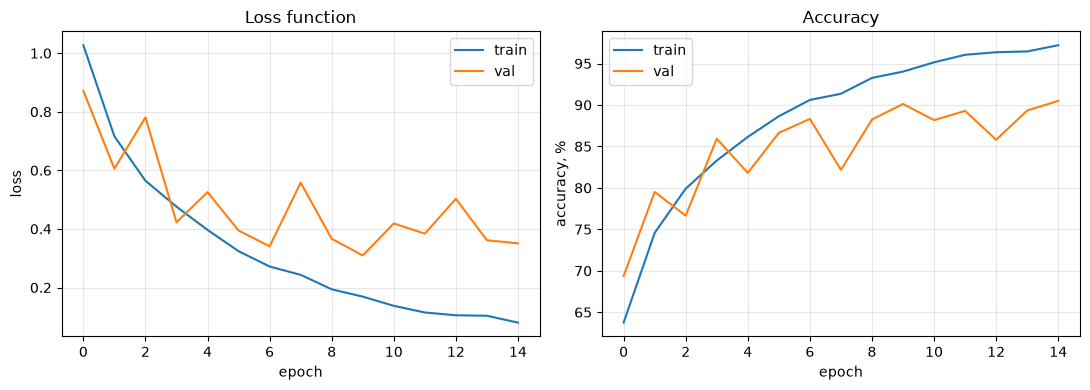

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(history["train_loss"], label="train")
axes[0].plot(history["val_loss"], label="val")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss")
axes[0].set_title("Loss function"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(history["train_acc"], label="train")
axes[1].plot(history["val_acc"], label="val")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy, %")
axes[1].set_title("Accuracy"); axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [13]:
model_pretrained = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model_pretrained.fc = nn.Linear(512, 10)
model_pretrained = model_pretrained.to(device)

n_params_pretrained = sum(p.numel() for p in model_pretrained.parameters())
print(f"Pretrained model parameters: {n_params_pretrained:,}")

Pretrained model parameters: 11,181,642


In [14]:
optimizer_pretrained = optim.Adam(model_pretrained.parameters(), lr=1e-3)

history_pretrained = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

for epoch in range(NUM_EPOCHS):
    train_loss, train_acc = run_epoch(model_pretrained, train_norm_loader, criterion, optimizer_pretrained)
    val_loss, val_acc = run_epoch(model_pretrained, val_norm_loader, criterion, optimizer=None)

    history_pretrained["train_loss"].append(train_loss)
    history_pretrained["train_acc"].append(train_acc)
    history_pretrained["val_loss"].append(val_loss)
    history_pretrained["val_acc"].append(val_acc)

    print(f"Epoch {epoch+1}/{NUM_EPOCHS}: "
          f"train_loss={train_loss:.4f} train_acc={train_acc:.2f}% | "
          f"val_loss={val_loss:.4f} val_acc={val_acc:.2f}%")

Epoch 1/15: train_loss=0.5156 train_acc=84.01% | val_loss=0.2538 val_acc=91.43%


Epoch 2/15: train_loss=0.2825 train_acc=90.94% | val_loss=0.2253 val_acc=92.07%


Epoch 3/15: train_loss=0.2243 train_acc=92.89% | val_loss=0.1750 val_acc=94.40%


Epoch 4/15: train_loss=0.1883 train_acc=93.91% | val_loss=0.2745 val_acc=90.52%


Epoch 5/15: train_loss=0.1614 train_acc=94.70% | val_loss=0.2382 val_acc=91.60%


...

Epoch 11/15: train_loss=0.0847 train_acc=97.26% | val_loss=0.2412 val_acc=93.19%


Epoch 12/15: train_loss=0.0679 train_acc=97.71% | val_loss=0.2129 val_acc=93.38%


Epoch 13/15: train_loss=0.0606 train_acc=98.03% | val_loss=0.2406 val_acc=93.33%


Epoch 14/15: train_loss=0.0583 train_acc=98.11% | val_loss=0.2274 val_acc=93.75%


Epoch 15/15: train_loss=0.0584 train_acc=98.25% | val_loss=0.2771 val_acc=92.52%


In [15]:
test_loss, test_acc = run_epoch(model_pretrained, test_norm_loader, criterion, optimizer=None)
print(f"Test loss: {test_loss:.4f}, Test accuracy: {test_acc:.2f}%")

Test loss: 0.2735, Test accuracy: 92.62%


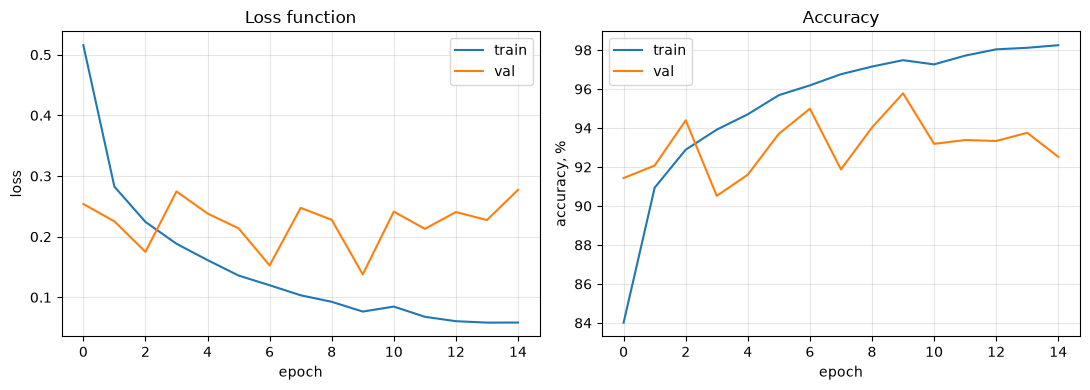

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(history_pretrained["train_loss"], label="train")
axes[0].plot(history_pretrained["val_loss"], label="val")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss")
axes[0].set_title("Loss function"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(history_pretrained["train_acc"], label="train")
axes[1].plot(history_pretrained["val_acc"], label="val")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy, %")
axes[1].set_title("Accuracy"); axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Задача 1.2. Стратегии дообучения: заморозка слоёв

Есть спектр стратегий между "обучить только последний слой" (feature extraction) и "дообучить всю
сеть целиком" (full fine-tuning). Сравните несколько точек на этом спектре.

1. **Только классификатор:** заморозьте (`requires_grad=False`) все веса, кроме `model.fc`.
2. **Последний блок + классификатор:** разморозьте также `model.layer4` (последний
   convolutional stage ResNet18).
3. **Полное дообучение:** разморозьте всё.
4. Сравните финальное качество, время обучения одной эпохи (заморозка экономит вычисления на
   backward pass!) и число обучаемых параметров для каждой стратегии.

In [ ]:
# TODO: сравнение стратегий заморозки слоёв (classifier_only/last_block/full)

Заморозка только классификатора

In [ ]:
model1 = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
# Замораживаем всё
for param in model1.parameters():
    param.requires_grad = False
# Размораживаем только fc
model1.fc = nn.Linear(512, 10)
for param in model1.fc.parameters():
    param.requires_grad = True
model1 = model1.to(device)


optimizer1 = optim.Adam(model1.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()


history1 = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

for epoch in range(NUM_EPOCHS):
    train_loss, train_acc = run_epoch(model1, train_norm_loader, criterion, optimizer1)
    val_loss, val_acc = run_epoch(model1, val_norm_loader, criterion, optimizer=None)

    history1["train_loss"].append(train_loss)
    history1["train_acc"].append(train_acc)
    history1["val_loss"].append(val_loss)
    history1["val_acc"].append(val_acc)

    print(f"Epoch {epoch+1}/{NUM_EPOCHS}: "
          f"train_loss={train_loss:.4f} train_acc={train_acc:.2f}% | "
          f"val_loss={val_loss:.4f} val_acc={val_acc:.2f}%")


Epoch 1/15: train_loss=0.8378 train_acc=74.09% | val_loss=0.4885 val_acc=84.86%


Epoch 2/15: train_loss=0.5729 train_acc=81.70% | val_loss=0.4391 val_acc=85.88%


Epoch 3/15: train_loss=0.5365 train_acc=82.62% | val_loss=0.4476 val_acc=85.75%


Epoch 4/15: train_loss=0.5101 train_acc=83.35% | val_loss=0.4226 val_acc=86.32%


Epoch 5/15: train_loss=0.5127 train_acc=82.99% | val_loss=0.4190 val_acc=86.22%


...

Epoch 11/15: train_loss=0.4814 train_acc=84.39% | val_loss=0.4622 val_acc=85.43%


Epoch 12/15: train_loss=0.4798 train_acc=84.20% | val_loss=0.4149 val_acc=86.54%


Epoch 13/15: train_loss=0.4753 train_acc=84.34% | val_loss=0.4166 val_acc=86.40%


Epoch 14/15: train_loss=0.4746 train_acc=84.31% | val_loss=0.4193 val_acc=86.59%


Epoch 15/15: train_loss=0.4718 train_acc=84.48% | val_loss=0.4444 val_acc=86.15%


Последний блок + классификатор

In [18]:
model2 = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
# Замораживаем всё
for param in model2.parameters():
    param.requires_grad = False

for param in model2.layer4.parameters():
    param.requires_grad = True
model2.fc = nn.Linear(512, 10)
for param in model2.fc.parameters():
    param.requires_grad = True
model2 = model2.to(device)

optimizer2 = optim.Adam(model2.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()


history2 = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

for epoch in range(NUM_EPOCHS):
    train_loss, train_acc = run_epoch(model2, train_norm_loader, criterion, optimizer2)
    val_loss, val_acc = run_epoch(model2, val_norm_loader, criterion, optimizer=None)

    history2["train_loss"].append(train_loss)
    history2["train_acc"].append(train_acc)
    history2["val_loss"].append(val_loss)
    history2["val_acc"].append(val_acc)

    print(f"Epoch {epoch+1}/{NUM_EPOCHS}: "
          f"train_loss={train_loss:.4f} train_acc={train_acc:.2f}% | "
          f"val_loss={val_loss:.4f} val_acc={val_acc:.2f}%")

Epoch 1/15: train_loss=0.3817 train_acc=87.73% | val_loss=0.1876 val_acc=93.38%


Epoch 2/15: train_loss=0.1849 train_acc=94.15% | val_loss=0.1538 val_acc=95.01%


Epoch 3/15: train_loss=0.1402 train_acc=95.38% | val_loss=0.1453 val_acc=95.33%


Epoch 4/15: train_loss=0.1103 train_acc=96.30% | val_loss=0.2106 val_acc=93.85%


Epoch 5/15: train_loss=0.0931 train_acc=96.95% | val_loss=0.1721 val_acc=94.86%


...

Epoch 11/15: train_loss=0.0483 train_acc=98.68% | val_loss=0.2016 val_acc=95.26%


Epoch 12/15: train_loss=0.0429 train_acc=98.68% | val_loss=0.2114 val_acc=95.21%


Epoch 13/15: train_loss=0.0387 train_acc=98.76% | val_loss=0.1963 val_acc=95.46%


Epoch 14/15: train_loss=0.0427 train_acc=98.74% | val_loss=0.2045 val_acc=94.99%


Epoch 15/15: train_loss=0.0285 train_acc=99.08% | val_loss=0.1994 val_acc=95.06%


In [25]:
n_params = sum(p.numel() for p in model_scratch.parameters() if p.requires_grad)
print(f"с нуля обучение: {n_params:,}")

n_params = sum(p.numel() for p in model1.parameters() if p.requires_grad)
print(f"обучение классификатора: {n_params:,}")

n_params = sum(p.numel() for p in model2.parameters() if p.requires_grad)
print(f"обучение классификатора + layer4: {n_params:,}")

с нуля обучение: 11,181,642
обучение классификатора: 5,130
обучение классификатора + layer4: 8,398,858


Время на обучение (15 эпох)\
обучение классификатора - 4 мин 30 сек\
обучение классификатора + layer4 - 5 мин 9 сек\
с нуля обучение - 7 минут

In [23]:
test_loss_scratch, test_acc_scratch = run_epoch(model_scratch, test_loader, criterion, optimizer=None)
test_loss_1, test_acc_1 = run_epoch(model1, test_norm_loader, criterion, optimizer=None)
test_loss_2, test_acc_2 = run_epoch(model2, test_norm_loader, criterion, optimizer=None)

In [26]:
print("\nС нуля обучение:")
print(f"Test loss: {test_loss_scratch:.4f}, Test accuracy: {test_acc_scratch:.2f}%")
print("\nОбучение классификатора:")
print(f"Test loss: {test_loss_1:.4f}, Test accuracy: {test_acc_1:.2f}%")
print("\nОбучение классификатора и последнего блока:")
print(f"Test loss: {test_loss_2:.4f}, Test accuracy: {test_acc_2:.2f}%")


С нуля обучение:
Test loss: 0.3751, Test accuracy: 90.35%

Обучение классификатора:
Test loss: 0.4491, Test accuracy: 86.05%

Обучение классификатора и последнего блока:
Test loss: 0.2031, Test accuracy: 94.64%


## Уровень 2. Средний

### Задача 2.1. U-Net с нуля для бинарной сегментации

U-Net — стандартная архитектура для сегментации: энкодер (сжимающий путь, как обычная CNN) +
декодер (разжимающий путь с транспонированными свёртками), плюс **skip-connections** между
соответствующими уровнями энкодера и декодера — без них декодер не может восстановить
пространственные детали, потерянные при пулинге.

1. Реализуйте `UNet` (можно использовать блок `DoubleConv = Conv-BN-ReLU-Conv-BN-ReLU`, 3-4
   уровня энкодера/декодера).
2. Обучите на подвыборке Oxford-IIIT Pet (бинарная маска "питомец vs фон", как в задаче 1.3).
3. Посчитайте IoU на test-подвыборке и сравните с наивным baseline из задачи 1.3.
4. Визуализируйте несколько предсказанных масок рядом с истинными.

In [ ]:
# TODO: UNet с нуля, обучение на Oxford-IIIT Pet, IoU, визуализация

---
**Что сдавать:** ноутбук с обученными моделями, графиками, визуализациями масок и письменными
ответами на вопросы для решённых задач. Полный прогон задач 2.1-3.3 на подвыборке Oxford-IIIT Pet
(1500 изображений, 128×128, 15 эпох) — порядка 40-60 минут на CPU, заметно быстрее на GPU Colab.
При нехватке времени уменьшите размер подвыборки/число эпох, сохранив логику сравнения.